In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv('/content/IPLPlayerStat.csv')

In [4]:
df.head()

,Unnamed: 0,player,runs,boundaries,balls_faced,wickets,balls_bowled,runs_conceded,matches,batting_avg,batting_strike_rate,boundaries_percent,bowling_economy,bowling_avg,bowling_strike_rate,catches,stumpings
0,0,A Ashish Reddy,280,31,196,18.0,270.0,400.0,28,10.00,142.86,15.82,8.89,22.22,15.00,8.0,0.0
1,1,A Badoni,161,18,139,2.0,12.0,12.0,11,14.64,115.83,12.95,6.00,6.00,6.00,8.0,0.0
2,2,A Chandila,4,0,7,11.0,234.0,245.0,12,0.33,57.14,0.00,6.28,22.27,21.27,2.0,0.0
3,3,A Chopra,53,7,75,0.0,0.0,0.0,6,8.83,70.67,9.33,0.00,0.00,0.00,2.0,0.0
4,4,A Choudhary,25,2,20,5.0,108.0,144.0,5,5.00,125.00,10.00,8.00,28.80,21.60,0.0,0.0


In [5]:
df.shape

(605, 17)

In [6]:
df['runs'].describe()

,runs
count,605.000000
mean,464.428099
std,985.272855
min,0.000000
25%,15.000000
50%,73.000000
75%,326.000000
max,6634.000000


# Log Transformation

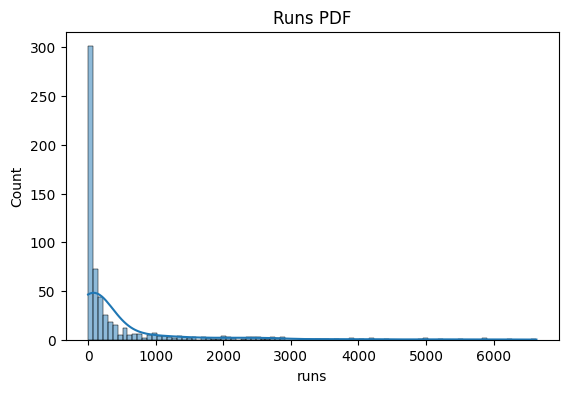

In [7]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(df['runs'],kde=True)
plt.title('Runs PDF')
plt.show()

In [9]:
df['runs_log']=np.log1p(df['runs']) #natural log
df['runs_log10'] = df['runs_log']/np.log(10)
df[['runs','runs_log','runs_log10']].head(10)

,runs,runs_log,runs_log10
0,280,5.638355,2.448706
1,161,5.087596,2.209515
2,4,1.609438,0.698970
3,53,3.988984,1.732394
4,25,3.258097,1.414973
5,4,1.609438,0.698970
6,62,4.143135,1.799341
7,35,3.583519,1.556303
8,108,4.691348,2.037426
9,362,5.894403,2.559907


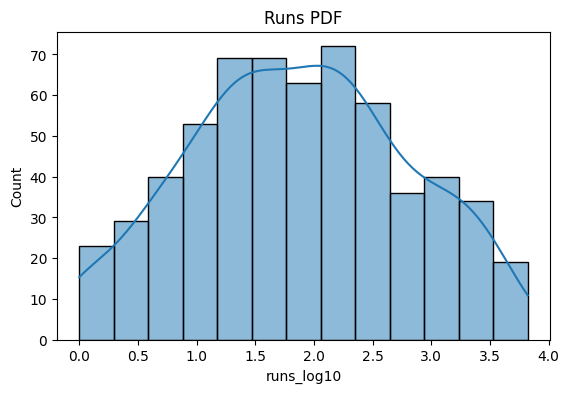

In [10]:
# Runs Distribution after log transformation

plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(df['runs_log10'],kde=True)
plt.title('Runs PDF')
plt.show()


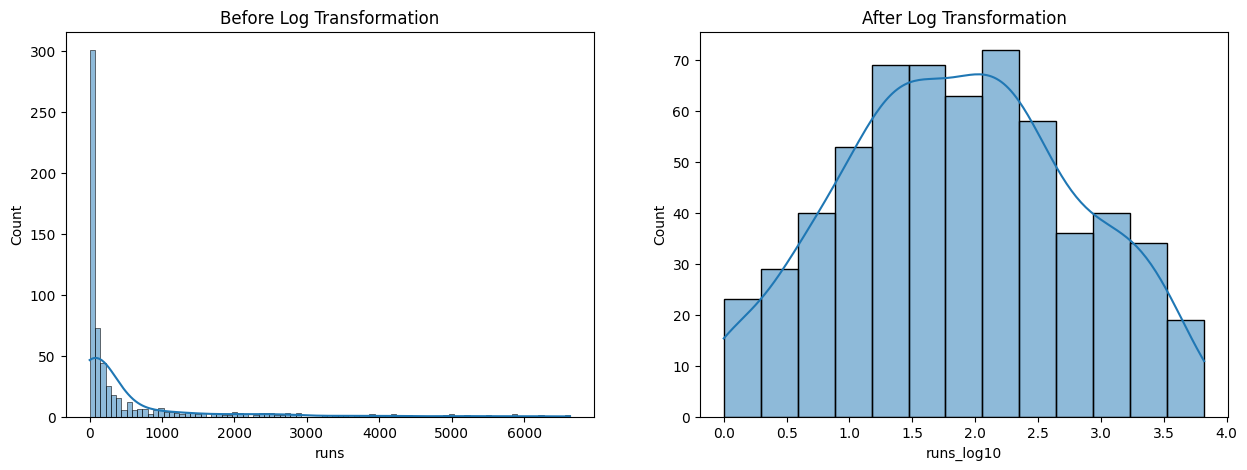

In [14]:
# Before Vs After Log Transformation

fig ,ax = plt.subplots(1,2,figsize=(15,5))

sns.histplot(df['runs'],kde=True,ax=ax[0])
ax[0].set_title('Before Log Transformation')

sns.histplot(df['runs_log10'],kde=True,ax=ax[1])
ax[1].set_title('After Log Transformation')

plt.show()

# Power Transformation

In [15]:
df['matches'].describe()

,matches
count,605.000000
mean,32.869421
std,42.215050
min,1.000000
25%,6.000000
50%,14.000000
75%,43.000000
max,221.000000


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import PowerTransformer

df = pd.read_csv('/content/IPLPlayerStat.csv')

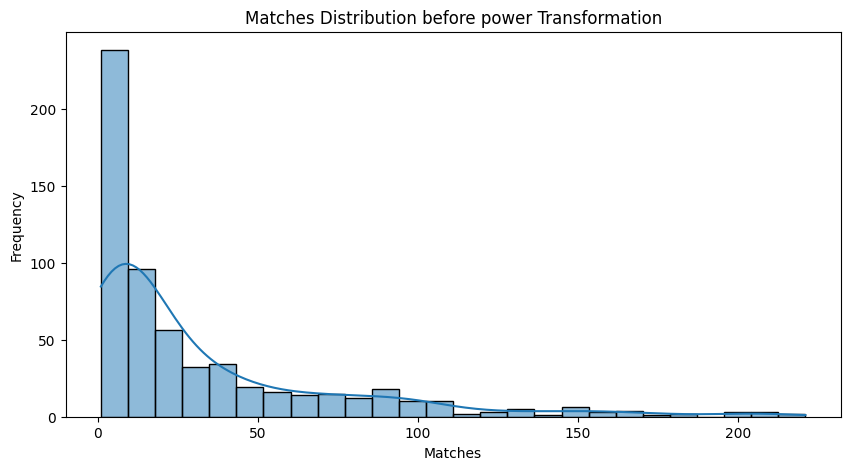

In [16]:
# Matches Distribution before power Transformation

plt.figure(figsize=(10,5))
sns.histplot(df['matches'],kde=True)

plt.title('Matches Distribution before power Transformation')
plt.xlabel('Matches')
plt.ylabel('Frequency')

plt.show()

In [20]:
pt=PowerTransformer(method='yeo-johnson')

df['matches_power']=pt.fit_transform(
    df[['matches']].astype(int)
)
print(pt.lambdas_)

[-0.04910143]


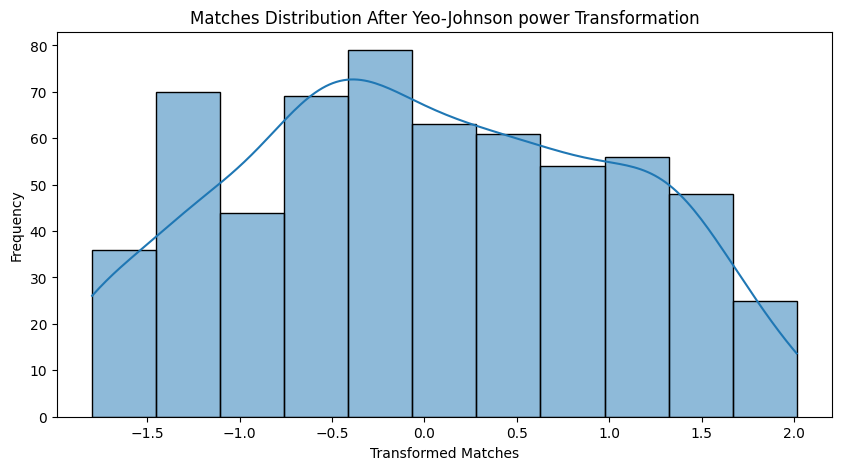

In [21]:
# Matches Distribution before power Transformation

plt.figure(figsize=(10,5))
sns.histplot(df['matches_power'],kde=True)

plt.title('Matches Distribution After Yeo-Johnson power Transformation')
plt.xlabel('Transformed Matches')
plt.ylabel('Frequency')

plt.show()

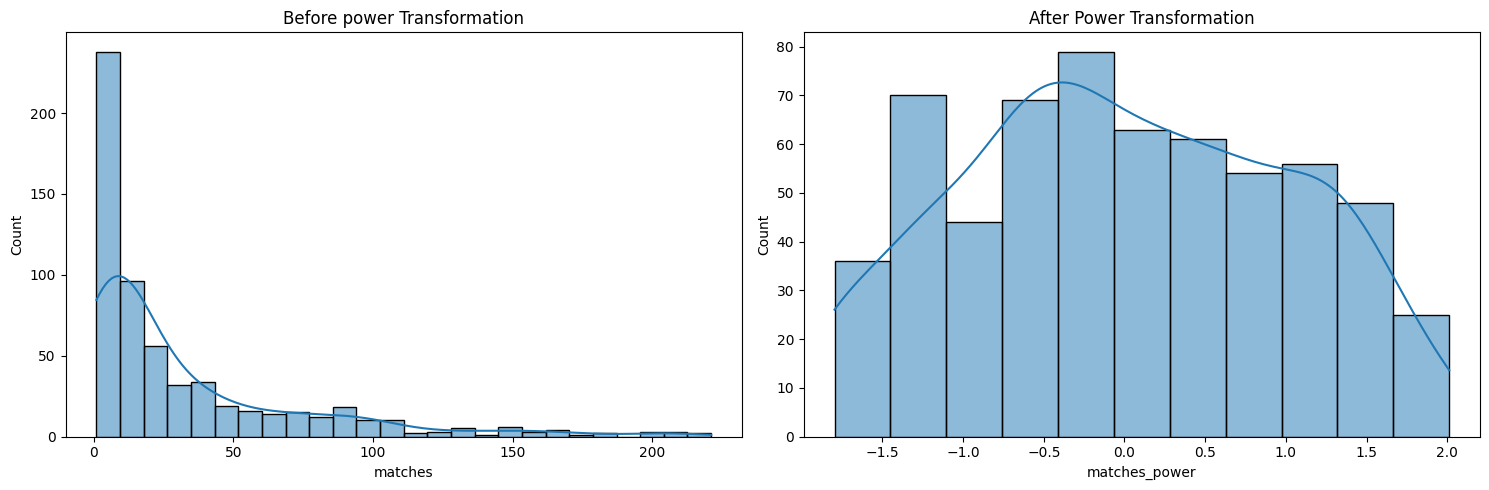

In [24]:
# Before Vs After Log Transformation

fig ,ax = plt.subplots(1,2,figsize=(15,5))

sns.histplot(df['matches'],kde=True,ax=ax[0])
ax[0].set_title('Before power Transformation')

sns.histplot(df['matches_power'],kde=True,ax=ax[1])
ax[1].set_title('After Power Transformation')

plt.tight_layout()
plt.show()

In [26]:
pt1= PowerTransformer(method='box-cox')

df['ball_faced_transformed']=pt1.fit_transform(
    df[['balls_faced']]
)
print(pt1.lambdas_)

[0.00040026]


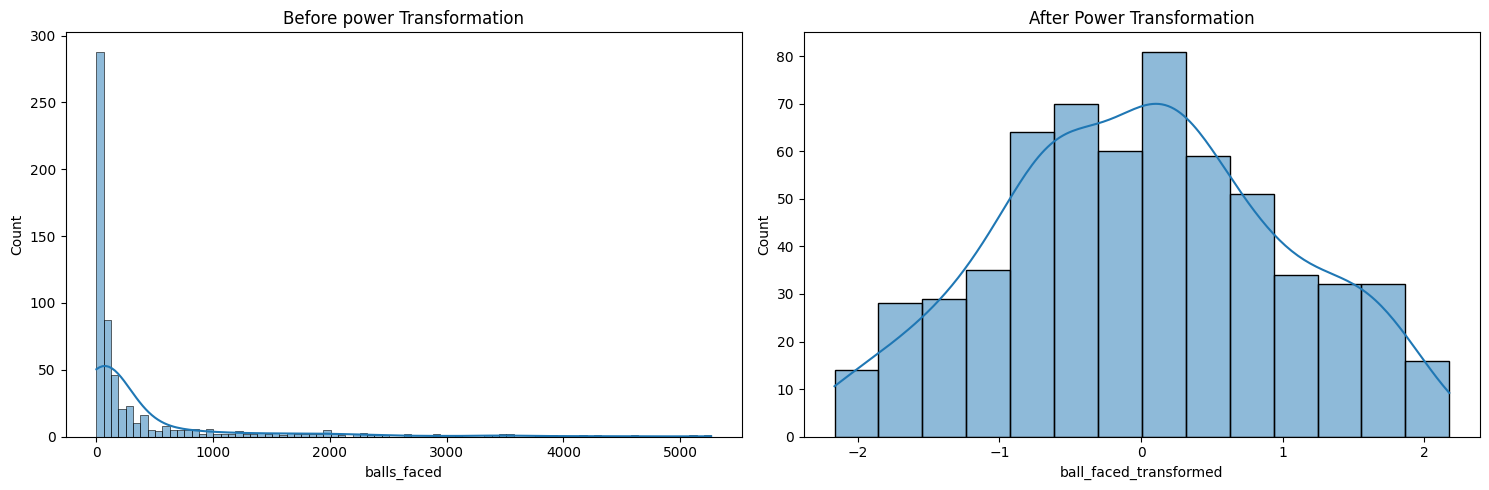

In [27]:
# Before Vs After Log Transformation

fig ,ax = plt.subplots(1,2,figsize=(15,5))

sns.histplot(df['balls_faced'],kde=True,ax=ax[0])
ax[0].set_title('Before power Transformation')

sns.histplot(df['ball_faced_transformed'],kde=True,ax=ax[1])
ax[1].set_title('After Power Transformation')

plt.tight_layout()
plt.show()

# Binning

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [29]:
df=pd.read_csv('/content/class_ipl_22-26_dataset.csv')

In [30]:
df.head()

,date,season,city,venue,team1,team2,toss_winner,toss_decision,team1_runs,team1_wickets,...,win_by_wickets,player_of_match,match_referee,umpire1,umpire2,tv_umpire,reserve_umpire,overs_limit,team1_players,team2_players
0,26-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Chennai Super Kings,Kolkata Knight Riders,Kolkata Knight Riders,field,131,5,...,6,UT Yadav,M Nayyar,AK Chaudhary,Nitin Menon,VK Sharma,Chirra Ravikanthreddy,20,"RD Gaikwad, DP Conway, RV Uthappa, AT Rayudu, ...","AM Rahane, VR Iyer, N Rana, SS Iyer, SW Billin..."
1,27-03-2022,2022,Mumbai,"Brabourne Stadium, Mumbai",Mumbai Indians,Delhi Capitals,Delhi Capitals,field,177,5,...,4,Kuldeep Yadav,Prakash Bhatt,RJ Tucker,HAS Khalid,J Madanagopal,N Pandit,20,"RG Sharma, Ishan Kishan, Anmolpreet Singh, Til...","PP Shaw, TL Seifert, Mandeep Singh, RR Pant, L..."
2,27-03-2022,2022,Mumbai,"Dr DY Patil Sports Academy, Mumbai",Royal Challengers Bangalore,Punjab Kings,Punjab Kings,field,205,2,...,5,OF Smith,M Nayyar,Nitin Menon,YC Barde,AK Chaudhary,R Pandit,20,"F du Plessis, Anuj Rawat, V Kohli, KD Karthik,...","MA Agarwal, S Dhawan, PBB Rajapaksa, LS Living..."
3,28-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Lucknow Super Giants,Gujarat Titans,Gujarat Titans,field,158,6,...,5,Mohammed Shami,DS Manohar,PG Pathak,VK Sharma,RJ Tucker,GR Sadashiv Iyer,20,"KL Rahul, Q de Kock, E Lewis, MK Pandey, DJ Ho...","Shubman Gill, MS Wade, V Shankar, HH Pandya, D..."
4,29-03-2022,2022,Pune,"Maharashtra Cricket Association Stadium, Pune",Rajasthan Royals,Sunrisers Hyderabad,Sunrisers Hyderabad,field,210,6,...,0,SV Samson,Shakti Singh,BNJ Oxenford,UV Gandhe,KN Ananthapadmanabhan,MV Saidharshan Kumar,20,"JC Buttler, YBK Jaiswal, SV Samson, D Padikkal...","KS Williamson, Abhishek Sharma, RA Tripathi, N..."


In [32]:
X = df[['team1_runs']]
X.head()

,team1_runs
0,131
1,177
2,205
3,158
4,210


In [34]:
# Create Bin
# low,medium,high,very high

bins= [0,120,160,200,df['team1_runs'].max()]
label = ['Low','Medium','High','Very High']

df['Runs_Category'] = pd.cut(
    df['team1_runs'],
    bins=bins,
    labels=label,
    include_lowest=True
)

df[['team1_runs','Runs_Category']].head(10)

,team1_runs,Runs_Category
0,131,Medium
1,177,High
2,205,Very High
3,158,Medium
4,210,Very High
5,128,Medium
6,210,Very High
7,137,Medium
8,171,High
9,193,High


In [35]:
df['Runs_Category'].value_counts().sort_index()

,count
Runs_Category,
Low,13
Medium,77
High,148
Very High,129


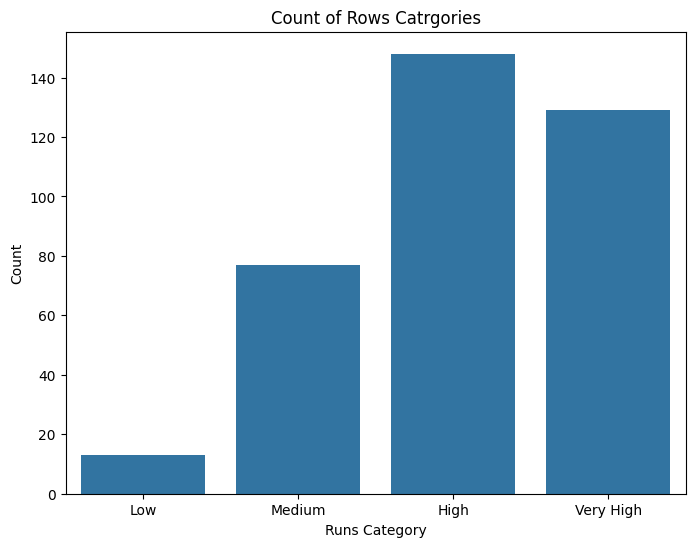

In [48]:
plt.figure(figsize=(8,6))

sns.countplot(x='Runs_Category',data=df)
plt.xlabel("Runs Category")
plt.ylabel('Count')
plt.title('Count of Rows Catrgories')
plt.show()

In [49]:
comparision = df[['team1_runs','Runs_Category']]
comparision.head()

,team1_runs,Runs_Category
0,131,Medium
1,177,High
2,205,Very High
3,158,Medium
4,210,Very High


# Binarization

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import Binarizer

df=pd.read_csv('/content/class_ipl_22-26_dataset.csv')
df.head()

,date,season,city,venue,team1,team2,toss_winner,toss_decision,team1_runs,team1_wickets,...,win_by_wickets,player_of_match,match_referee,umpire1,umpire2,tv_umpire,reserve_umpire,overs_limit,team1_players,team2_players
0,26-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Chennai Super Kings,Kolkata Knight Riders,Kolkata Knight Riders,field,131,5,...,6,UT Yadav,M Nayyar,AK Chaudhary,Nitin Menon,VK Sharma,Chirra Ravikanthreddy,20,"RD Gaikwad, DP Conway, RV Uthappa, AT Rayudu, ...","AM Rahane, VR Iyer, N Rana, SS Iyer, SW Billin..."
1,27-03-2022,2022,Mumbai,"Brabourne Stadium, Mumbai",Mumbai Indians,Delhi Capitals,Delhi Capitals,field,177,5,...,4,Kuldeep Yadav,Prakash Bhatt,RJ Tucker,HAS Khalid,J Madanagopal,N Pandit,20,"RG Sharma, Ishan Kishan, Anmolpreet Singh, Til...","PP Shaw, TL Seifert, Mandeep Singh, RR Pant, L..."
2,27-03-2022,2022,Mumbai,"Dr DY Patil Sports Academy, Mumbai",Royal Challengers Bangalore,Punjab Kings,Punjab Kings,field,205,2,...,5,OF Smith,M Nayyar,Nitin Menon,YC Barde,AK Chaudhary,R Pandit,20,"F du Plessis, Anuj Rawat, V Kohli, KD Karthik,...","MA Agarwal, S Dhawan, PBB Rajapaksa, LS Living..."
3,28-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Lucknow Super Giants,Gujarat Titans,Gujarat Titans,field,158,6,...,5,Mohammed Shami,DS Manohar,PG Pathak,VK Sharma,RJ Tucker,GR Sadashiv Iyer,20,"KL Rahul, Q de Kock, E Lewis, MK Pandey, DJ Ho...","Shubman Gill, MS Wade, V Shankar, HH Pandya, D..."
4,29-03-2022,2022,Pune,"Maharashtra Cricket Association Stadium, Pune",Rajasthan Royals,Sunrisers Hyderabad,Sunrisers Hyderabad,field,210,6,...,0,SV Samson,Shakti Singh,BNJ Oxenford,UV Gandhe,KN Ananthapadmanabhan,MV Saidharshan Kumar,20,"JC Buttler, YBK Jaiswal, SV Samson, D Padikkal...","KS Williamson, Abhishek Sharma, RA Tripathi, N..."


In [54]:
X = df[['team1_runs']]
X.head()


,team1_runs
0,131
1,177
2,205
3,158
4,210


In [55]:
binarizer = Binarizer(threshold=160)


In [56]:
x_binary = binarizer.fit_transform(X)

x_binary = pd.DataFrame(x_binary,columns=['team1_runs'])

x_binary.head()

,team1_runs
0,0
1,1
2,1
3,0
4,1


In [57]:
# Comparision

Comparision = pd.DataFrame({
    'Original':X['team1_runs'],
    'Binarized':x_binary['team1_runs']
})

Comparision.head(10)

,Original,Binarized
0,131,0
1,177,1
2,205,1
3,158,0
4,210,1
5,128,0
6,210,1
7,137,0
8,171,1
9,193,1


In [59]:
Comparision['Binarized'].value_counts()

,count
Binarized,
1,277
0,90


/tmp/ipykernel_915/2916605053.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='team1_runs',data=x_binary,palette='viridis')


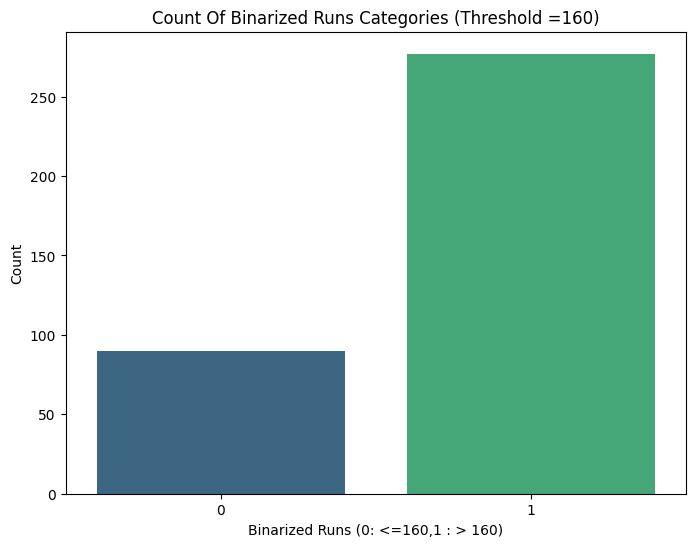

In [60]:
plt.figure(figsize=(8,6))
sns.countplot(x='team1_runs',data=x_binary,palette='viridis')

plt.title('Count Of Binarized Runs Categories (Threshold =160)')
plt.xlabel('Binarized Runs (0: <=160,1 : > 160)')
plt.ylabel('Count')
plt.xticks(ticks=[0,1],labels=['0','1'])
plt.show()

# Column Transformation

In [61]:
import pandas as pd

from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder

from sklearn.preprocessing import StandardScaler

df=pd.read_csv('/content/class_ipl_22-26_dataset.csv')
df.head()

,date,season,city,venue,team1,team2,toss_winner,toss_decision,team1_runs,team1_wickets,...,win_by_wickets,player_of_match,match_referee,umpire1,umpire2,tv_umpire,reserve_umpire,overs_limit,team1_players,team2_players
0,26-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Chennai Super Kings,Kolkata Knight Riders,Kolkata Knight Riders,field,131,5,...,6,UT Yadav,M Nayyar,AK Chaudhary,Nitin Menon,VK Sharma,Chirra Ravikanthreddy,20,"RD Gaikwad, DP Conway, RV Uthappa, AT Rayudu, ...","AM Rahane, VR Iyer, N Rana, SS Iyer, SW Billin..."
1,27-03-2022,2022,Mumbai,"Brabourne Stadium, Mumbai",Mumbai Indians,Delhi Capitals,Delhi Capitals,field,177,5,...,4,Kuldeep Yadav,Prakash Bhatt,RJ Tucker,HAS Khalid,J Madanagopal,N Pandit,20,"RG Sharma, Ishan Kishan, Anmolpreet Singh, Til...","PP Shaw, TL Seifert, Mandeep Singh, RR Pant, L..."
2,27-03-2022,2022,Mumbai,"Dr DY Patil Sports Academy, Mumbai",Royal Challengers Bangalore,Punjab Kings,Punjab Kings,field,205,2,...,5,OF Smith,M Nayyar,Nitin Menon,YC Barde,AK Chaudhary,R Pandit,20,"F du Plessis, Anuj Rawat, V Kohli, KD Karthik,...","MA Agarwal, S Dhawan, PBB Rajapaksa, LS Living..."
3,28-03-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Lucknow Super Giants,Gujarat Titans,Gujarat Titans,field,158,6,...,5,Mohammed Shami,DS Manohar,PG Pathak,VK Sharma,RJ Tucker,GR Sadashiv Iyer,20,"KL Rahul, Q de Kock, E Lewis, MK Pandey, DJ Ho...","Shubman Gill, MS Wade, V Shankar, HH Pandya, D..."
4,29-03-2022,2022,Pune,"Maharashtra Cricket Association Stadium, Pune",Rajasthan Royals,Sunrisers Hyderabad,Sunrisers Hyderabad,field,210,6,...,0,SV Samson,Shakti Singh,BNJ Oxenford,UV Gandhe,KN Ananthapadmanabhan,MV Saidharshan Kumar,20,"JC Buttler, YBK Jaiswal, SV Samson, D Padikkal...","KS Williamson, Abhishek Sharma, RA Tripathi, N..."


In [65]:
X= df[['team1_runs','toss_decision','team1_wickets','win_by_wickets']]
X.head()

,team1_runs,toss_decision,team1_wickets,win_by_wickets
0,131,field,5,6
1,177,field,5,4
2,205,field,2,5
3,158,field,6,5
4,210,field,6,0


In [66]:
# Create Column Transformer

from sklearn.pipeline import Pipeline

transformers =[
    (
        'num',
        SimpleImputer(strategy='mean'),
        ['team1_runs']
    ),
    (
        'scale',
        StandardScaler(),
        ['team1_wickets']
    ),
    (
        'cat',
        Pipeline(
            [
                (
                    'imputer',SimpleImputer(strategy='most_frequent')
                ),
                (
                    'encoder',OneHotEncoder()
                )
            ]
        ),
        ['toss_decision']
    ),
    (
        'details',
        'passthrough',
        ['win_by_wickets']
    )

]

transformer = ColumnTransformer(transformers= transformers)


In [69]:
x_transformed = transformer.fit_transform(X)
print(type(x_transformed))

x_transformed = pd.DataFrame(x_transformed,columns=['team1_runs','team1_wickets','toss_decision_bat','toss_decision_field','win_by_wickets'])
x_transformed

<class 'numpy.ndarray'>


,team1_runs,team1_wickets,toss_decision_bat,toss_decision_field,win_by_wickets
0,131.0,-0.572377,0.0,1.0,6.0
1,177.0,-0.572377,0.0,1.0,4.0
2,205.0,-1.954365,0.0,1.0,5.0
3,158.0,-0.111714,0.0,1.0,5.0
4,210.0,-0.111714,0.0,1.0,0.0
...,...,...,...,...,...
362,203.0,-0.572377,0.0,1.0,0.0
363,254.0,-0.572377,0.0,1.0,0.0
364,243.0,0.809612,0.0,1.0,0.0
365,214.0,-0.111714,1.0,0.0,7.0


In [72]:
print("Original Shape:",X.shape)
print("Transfomed Shape:",x_transformed.shape)

Original Shape: (367, 4)
Transfomed Shape: (367, 5)
